# Exploratory analysis

This notebook computes production-level distributions and group comparisons from the authorized workbook. All comparisons are descriptive and do not identify causal effects.

In [1]:
from pathlib import Path
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent.resolve()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from broadway_research.ingest import load

# Public clones must supply the authorized six-sheet workbook separately.
# Set BROADWAY_INPUT_DIR to the directory containing that workbook.
input_value = os.environ.get("BROADWAY_INPUT_DIR")
if not input_value:
    raise FileNotFoundError("Set BROADWAY_INPUT_DIR to the authorized workbook directory.")
input_dir = Path(input_value)
if not input_dir.exists() or not list(input_dir.glob("*.xlsx")):
    raise FileNotFoundError(
        "Authorized source workbook not found. Set BROADWAY_INPUT_DIR to its containing directory. "
        "The workbook is intentionally excluded from the public repository."
    )

production, market = load(input_dir)
print(f"Loaded authorized inputs: {production.shape[0]} production aggregates and {market.shape[0]} market weeks")

Loaded authorized inputs: 67 production aggregates and 501 market weeks


In [2]:
summary = production[["Avg_Gross_USD", "log_gross", "log_seats", "Observed_Weeks"]].describe().T
summary

,count,mean,std,min,25%,50%,75%,max
Avg_Gross_USD,67.0,838824.721045,448529.392625,172616.360000,534492.225000,797997.930000,1.019870e+06,2.677739e+06
log_gross,67.0,13.508025,0.527637,12.058827,13.189029,13.589861,1.383515e+01,1.480048e+01
log_seats,67.0,7.071388,0.275529,6.368187,6.926553,7.037028,7.309546e+00,7.535830e+00
Observed_Weeks,67.0,74.208955,74.159234,8.000000,20.000000,46.000000,8.300000e+01,2.480000e+02


In [3]:
style_counts = production["Music_Style"].value_counts().rename_axis("music_style").to_frame("productions")
style_counts

,productions
music_style,
Traditional,27
Pop/Rock,24
Mixed/Other,6
Folk/Country,5
Jazz/Swing,4
HipHop,1


In [4]:
group_stats = []
for variable in ["Adapted", "Revival"]:
    grouped = production.groupby(variable)["Avg_Gross_USD"]
    frame = grouped.agg(["count", "mean", "median", "std", "sem"]).reset_index()
    frame["variable"] = variable
    frame["ci95_low"] = frame["mean"] - 1.96 * frame["sem"]
    frame["ci95_high"] = frame["mean"] + 1.96 * frame["sem"]
    group_stats.append(frame.rename(columns={variable: "value"}))
group_stats = pd.concat(group_stats, ignore_index=True)
group_stats[["variable", "value", "count", "mean", "median", "ci95_low", "ci95_high"]]

,variable,value,count,mean,median,ci95_low,ci95_high
0,Adapted,0,14,614752.900714,495544.780,416423.941983,8.130819e+05
1,Adapted,1,53,898013.503774,831829.140,776886.285765,1.019141e+06
2,Revival,0,46,867113.018913,826921.375,726055.920924,1.008170e+06
3,Revival,1,21,776859.878095,728618.910,627497.926178,9.262218e+05


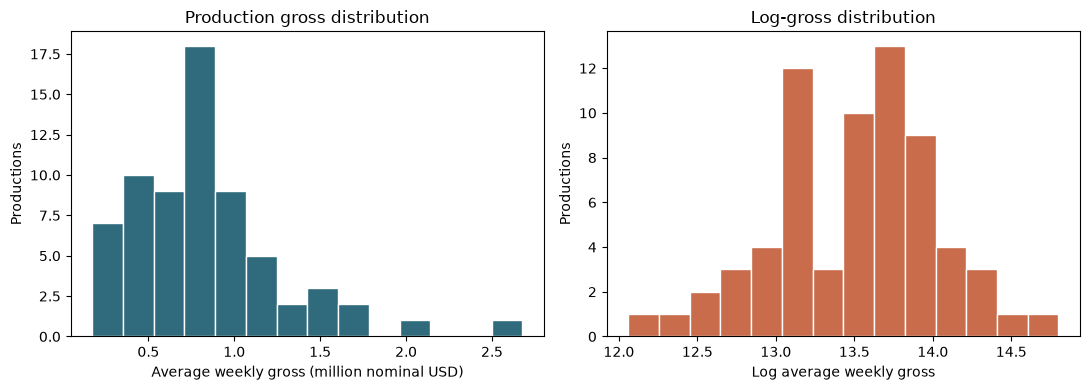

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(production["Avg_Gross_USD"] / 1e6, bins=14, color="#2f6b7c", edgecolor="white")
axes[0].set(xlabel="Average weekly gross (million nominal USD)", ylabel="Productions", title="Production gross distribution")
axes[1].hist(production["log_gross"], bins=14, color="#c96c4b", edgecolor="white")
axes[1].set(xlabel="Log average weekly gross", ylabel="Productions", title="Log-gross distribution")
fig.tight_layout();

In [6]:
capacity_corr = production[["log_seats", "log_gross"]].corr().iloc[0, 1]
simple_slope = np.polyfit(production["log_seats"], production["log_gross"], 1)[0]
pd.Series({
    "log_seats_log_gross_correlation": capacity_corr,
    "descriptive_bivariate_log_log_slope": simple_slope,
})

log_seats_log_gross_correlation        0.603117
descriptive_bivariate_log_log_slope    1.154966
dtype: float64

The bivariate slope above is a descriptive relationship and is not the coefficient from the multivariable replication model. Theatre allocation, pricing, demand, and production scale can jointly influence capacity and gross.